In [19]:
import rustworkx as rx
import numpy as np
from rustworkx.visualization import mpl_draw as draw_graph

np.random.seed(0)
n = 20  # Number of nodes
edge_prob = 0.25  # Probability of edge between any pair of nodes

adj_matrix = np.triu((np.random.rand(n, n) < edge_prob).astype(float), 1)
adj_matrix += adj_matrix.T
# adj_matrix

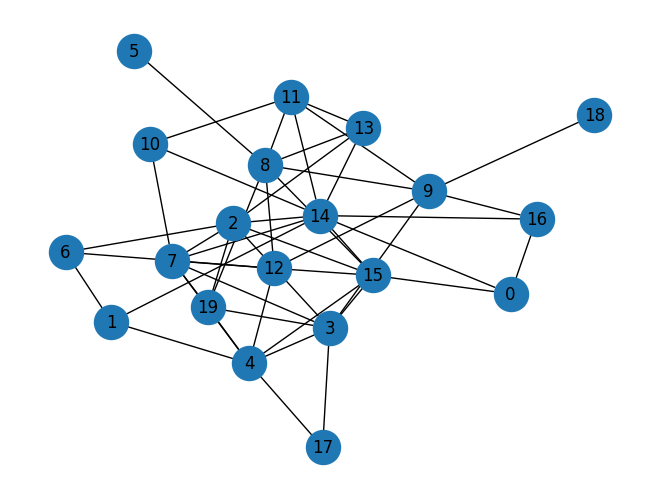

In [20]:
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)
draw_graph(graph, node_size=600, with_labels=True)

In [21]:
import networkx as nx

graph_nx = nx.from_numpy_array(adj_matrix)
cut_value, partition = nx.algorithms.approximation.maxcut.one_exchange(graph_nx)
print("Cut value:", cut_value)

Cut value: 36


In [22]:
def evaluate_cut(graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v, weight in graph.weighted_edge_list():
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += weight
    return cut_value

In [23]:
import matplotlib.pyplot as plt

def plot_graph_cut(G, x):
    colors = []
    for i in range(n):
        if x[i] == '0' or x[i] == 0:
            colors.append("tab:grey") 
        else:
            colors.append("tab:purple")
    pos, default_axes = rx.spring_layout(G, seed=0), plt.axes(frameon=True)
    rx.visualization.mpl_draw(G, node_color=colors, node_size=600, alpha=0.8, pos=pos, with_labels=True)

In [24]:
# import itertools

# def maxcut_brute_force(graph):
#     n = graph.num_nodes()
#     max_value = float('-inf')
#     best_cut = None

#     # Iterate over all possible bitstrings of length n
#     for bits in itertools.product("01", repeat=n):
#         bitstring = ''.join(bits)
#         value = evaluate_cut(graph, bitstring)
#         if value > max_value:
#             max_value = value
#             best_cut = bitstring

#     return max_value, best_cut

# max_value, best_bitstring = maxcut_brute_force(graph)
# print(f"MaxCut value: {max_value}")
# print(f"Best cut bitstring: {best_bitstring}")
# plot_graph_cut(graph, best_bitstring)

In [25]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    """Convert the graph to Pauli list.

    This function does the inverse of `build_max_cut_graph`
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIZIIIIIIIIIIIIIZ', 'IIIIZIIIIIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIZIIZI', 'IIIIIIIIIIIIIZIIIIZI', 'IIIIIZIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIZZII', 'IIIIIIIIIIIIIZIIIZII', 'IIIIIIIIIIIIZIIIIZII', 'IIIIIIZIIIIIIIIIIZII', 'IIIIIZIIIIIIIIIIIZII', 'IIIIZIIIIIIIIIIIIZII', 'ZIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIIIIIZZIII', 'IIIIIIIIIIIIZIIIZIII', 'IIIIIIIIIIZIIIIIZIII', 'IIIIZIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIZIIZIIII', 'IIIIIIIZIIIIIIIZIIII', 'IIIIZIIIIIIIIIIZIIII', 'IIZIIIIIIIIIIIIZIIII', 'ZIIIIIIIIIIIIIIZIIII', 'IIIIIIIIIIIZIIZIIIII', 'IIIIIIIZIIIIIZIIIIII', 'IIIIIIIIIZIIZIIIIIII', 'IIIIIIIZIIIIZIIIIIII', 'IIIIIZIIIIIIZIIIIIII', 'ZIIIIIIIIIIIZIIIIIII', 'IIIIIIIIIIZZIIIIIIII', 'IIIIIIIIZIIZIIIIIIII', 'IIIIIIIZIIIZIIIIIIII', 'IIIIIIZIIIIZIIIIIIII', 'IIIIZIIIIIIZIIIIIIII', 'ZIIIIIIIIIIZIIIIIIII', 'IIIIIIIIZIZIIIIIIIII', 'IIIIIIIZIIZIIIIIIIII', 'IIIZIIIIIIZIIIIIIIII', 'IZIIIIIIIIZIIIIIIIII'

In [26]:
from qiskit.circuit.library import QAOAAnsatz

reps=5
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
circuit.measure_all()

# circuit.draw('mpl')

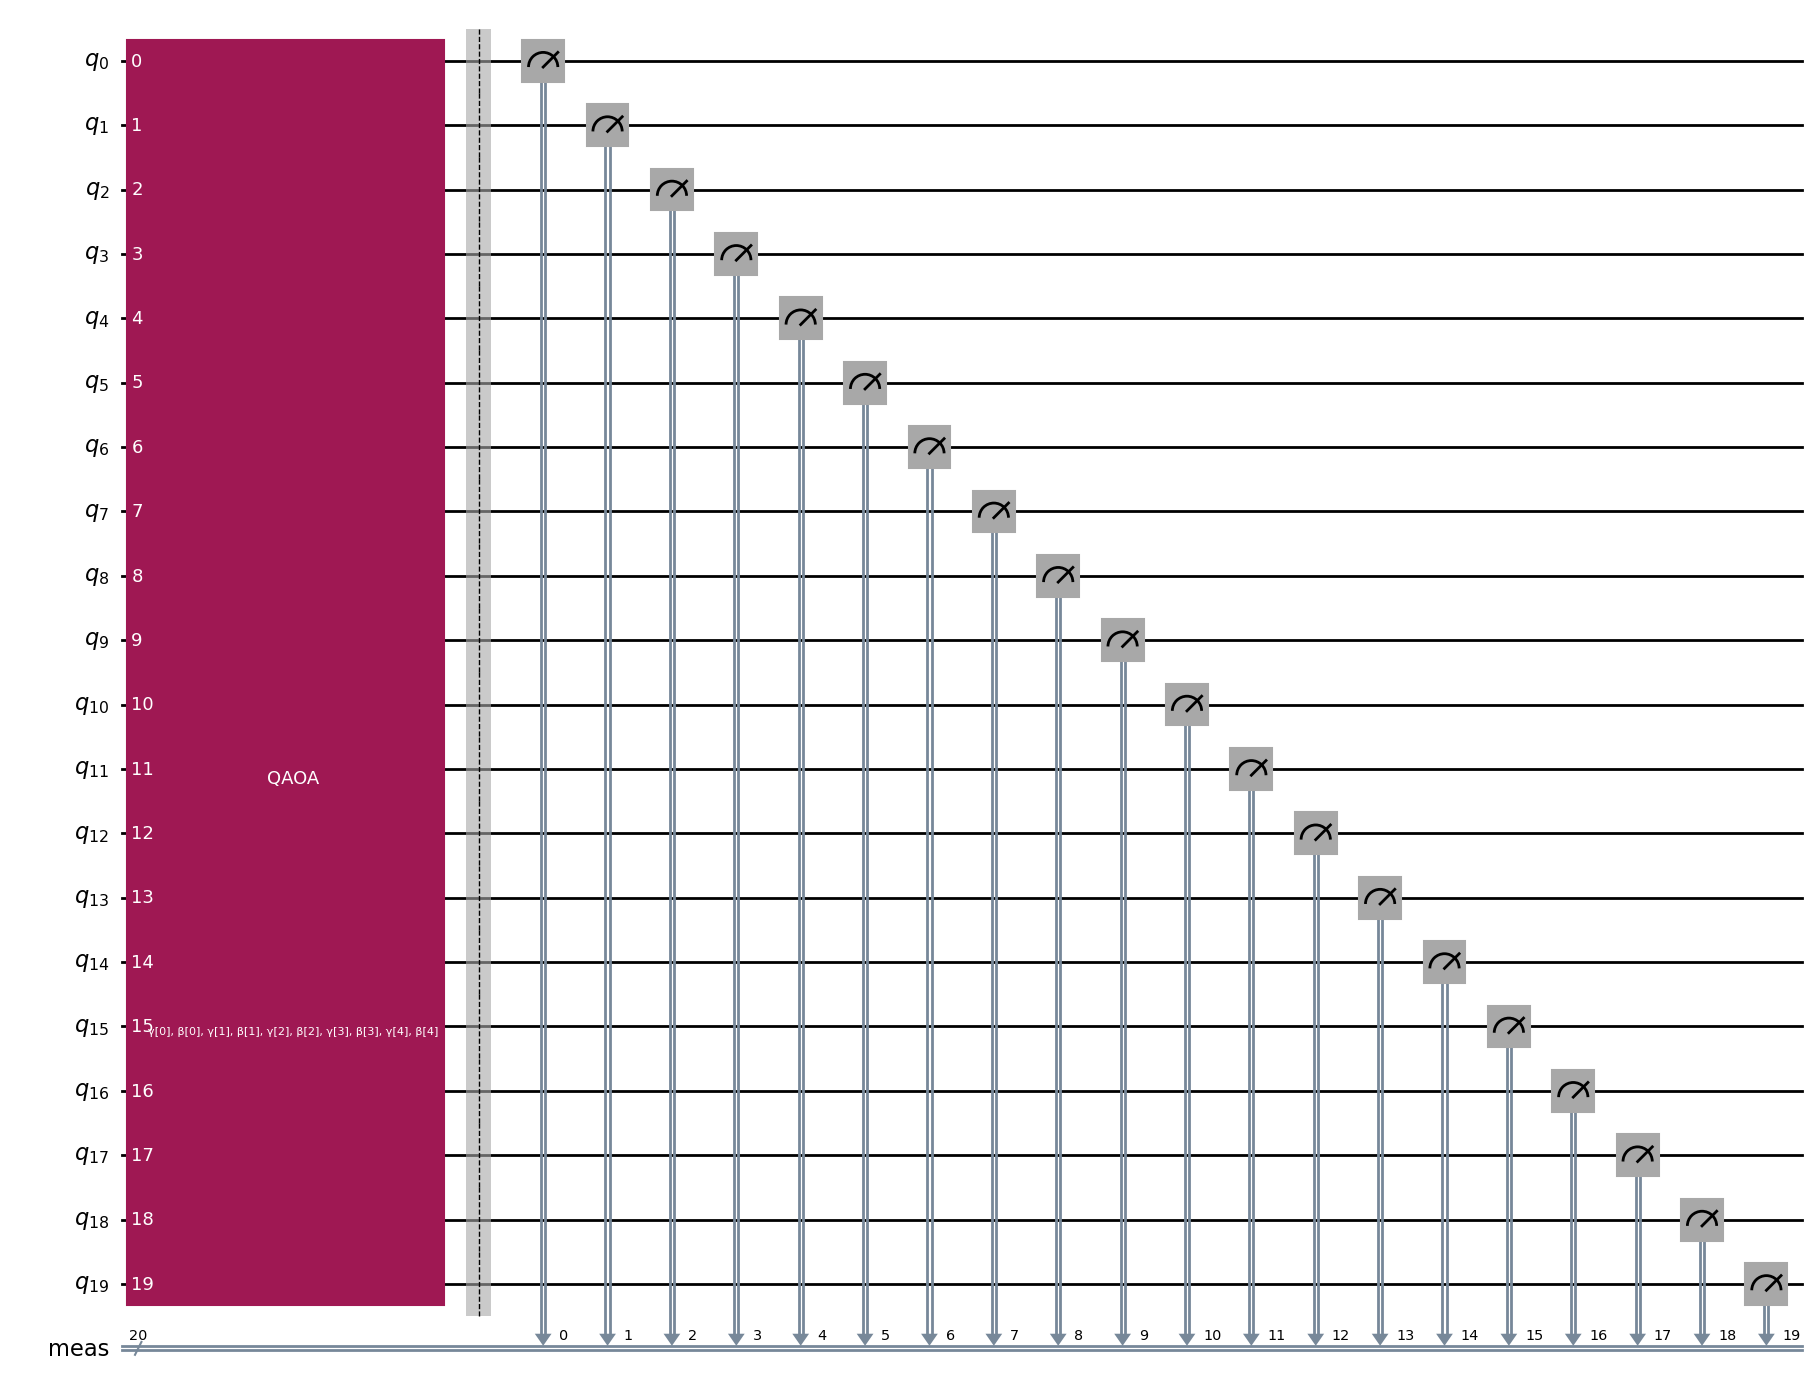

In [34]:
circuit.draw('mpl', fold=False)

In [37]:
circuit_d = circuit.decompose(reps=3)
circuit_d.draw('mpl', fold=False)

Initialize Params

In [9]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [10]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [45]:
from qiskit_ibm_runtime import QiskitRuntimeService

# QiskitRuntimeService.save_account(channel="ibm_quantum", token="<MY_IBM_QUANTUM_TOKEN>", overwrite=True, set_as_default=True)
service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')
backend = service.least_busy(min_num_qubits=127)
print(backend)

C:\Users\devra\AppData\Local\Temp\ipykernel_39500\1015567690.py:4: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud" and "local" will be the only valid channels. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')


<IBMBackend('ibm_brisbane')>


In [38]:
backend.coupling_map

In [50]:
print(backend.basis_gates)

['ecr', 'id', 'rz', 'sx', 'x']


In [78]:
# from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# backend = FakeManilaV2()

In [46]:
from qiskit_aer import AerSimulator

sim = AerSimulator.from_backend(backend)

In [49]:
print(sim._basis_gates)

<bound method AerSimulator._basis_gates of AerSimulator('aer_simulator_from(ibm_brisbane)'
             noise_model=<NoiseModel on ['measure', 'ecr', 'reset', 'x', 'id', 'sx']>)>


In [55]:
coupling_map = backend.coupling_map

# Get adjacency as a dict: {qubit: [connected_qubits]}
adj = {i: [] for i in range(backend.configuration().num_qubits)}
for (i, j) in coupling_map:
    adj[i].append(j)
    adj[j].append(i)

# Greedy DFS to build a chain
def find_linear_chain(adj, length):
    for start in adj:
        path = [start]
        visited = {start}
        while len(path) < length:
            last = path[-1]
            next_nodes = [n for n in adj[last] if n not in visited]
            if not next_nodes:
                break
            next_node = next_nodes[0]
            path.append(next_node)
            visited.add(next_node)
        if len(path) == length:
            return path
    return None

chain = find_linear_chain(adj, n)  # Length = number of qubits = nodes
chain

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 17, 30, 29, 28, 27, 26, 16]

In [52]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import transpile

# pm = generate_preset_pass_manager(backend=sim, optimization_level=3)
# candidate_circuit = pm.run(circuit)

candidate_circuit = transpile(circuit, backend=sim)

In [53]:
candidate_circuit.draw('mpl', fold=False)

In [ ]:
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    # estimator.options.dynamical_decoupling.enable = True
    # estimator.options.dynamical_decoupling.sequence_type = "XY4"
    # estimator.options.twirling.enable_gates = True
    # estimator.options.twirling.num_randomizations = "auto"
    estimator.options

    result = minimize(
        cost_func_estimator,
        init_params,
        args=(candidate_circuit, cost_hamiltonian, estimator),
        method="COBYLA",
        tol=1e-2,
    )
    print(result)

IBMRuntimeError: 'Failed to run program: \'400 Client Error: Bad Request for url: https://api.quantum.ibm.com/runtime/jobs. {"errors":[{"code":1217,"message":"Session has been closed.","solution":"Reduce time between submitting subsequent jobs in a session.","more_info":"https://docs.quantum-computing.ibm.com/errors"}]}\''

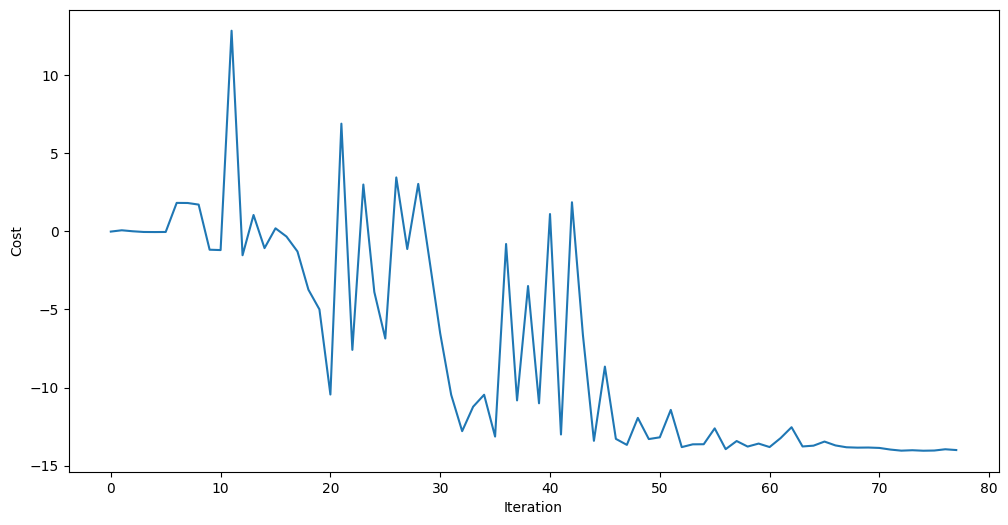

In [82]:
plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()



In [83]:
optimized_circuit = candidate_circuit.assign_parameters(result.x)
optimized_circuit.draw('mpl', fold=False, idle_wires=False)

In [84]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

# If using qiskit-ibm-runtime<0.24.0, change `mode=` to `backend=`
sampler = Sampler(mode=backend)
sampler.options.default_shots = 10000

# # Set simple error suppression/mitigation options
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.dynamical_decoupling.sequence_type = "XY4"
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.num_randomizations = "auto"

pub= (optimized_circuit, )
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{464159: 0.0001, 592039: 0.0001, 772660: 0.0001, 836944: 0.0001, 760487: 0.0003, 341279: 0.0014, 877000: 0.0001, 40510: 0.0001, 51960: 0.0001, 633570: 0.0006, 178855: 0.0002, 505226: 0.0002, 546575: 0.0001, 370062: 0.0001, 283964: 0.0001, 633962: 0.0002, 1041282: 0.0001, 301524: 0.0001, 283933: 0.0014, 376042: 0.0001, 502218: 0.0006, 1019466: 0.0001, 761366: 0.0002, 81471: 0.0001, 22357: 0.0002, 772832: 0.0004, 285077: 0.0002, 1031330: 0.0008, 771460: 0.0001, 1031334: 0.0003, 522472: 0.0001, 1031362: 0.0001, 939815: 0.0001, 572421: 0.0001, 455335: 0.0001, 959939: 0.0001, 354139: 0.0001, 307595: 0.0001, 1030314: 0.0006, 939337: 0.0003, 815729: 0.0001, 1030370: 0.0005, 141149: 0.0001, 15485: 0.0001, 30492: 0.0002, 940596: 0.0002, 377223: 0.0001, 232070: 0.0001, 87037: 0.0001, 750120: 0.0001, 969440: 0.0007, 1040618: 0.0001, 30969: 0.0001, 960163: 0.0002, 91114: 0.0001, 19417: 0.0003, 556153: 0.0001, 696035: 0.0001, 362950: 0.0001, 760486: 0.0007, 601879: 0.0001, 269599: 0.0004, 977520: 0

In [85]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(graph))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

Result bitstring: [0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1]


In [86]:
# import matplotlib.pyplot as plt
# import matplotlib

# matplotlib.rcParams.update({"font.size": 10})
# final_bits = final_distribution_bin
# values = np.abs(list(final_bits.values()))
# top_4_values = sorted(values, reverse=True)[:4]
# positions = []
# for value in top_4_values:
#     positions.append(np.where(values == value)[0])
# fig = plt.figure(figsize=(11, 6))
# ax = fig.add_subplot(1, 1, 1)
# plt.xticks(rotation=45)
# plt.title("Result Distribution")
# plt.xlabel("Bitstrings (reversed)")
# plt.ylabel("Probability")
# ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")
# for p in positions:
#     ax.get_children()[int(p)].set_color("tab:purple")
# plt.show()

Cut value = 36.0


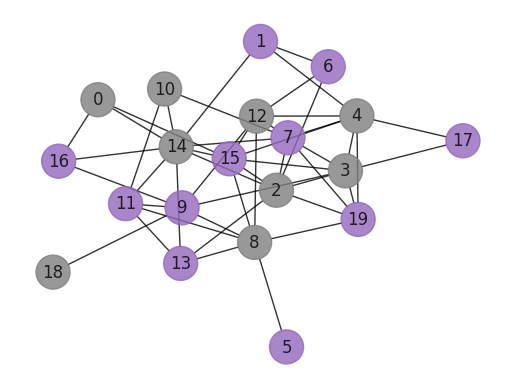

In [87]:
print(f"Cut value = {evaluate_cut(graph, most_likely_bitstring)}")
plot_graph_cut(graph, most_likely_bitstring)